# Radiation damping

Radiation damping is the feedback of the probe on the spins: the transverse
magnetisation induces a current in the coil, and the field of that current
rotates the magnetisation back towards equilibrium. The field depends on the
state, so the equation of motion is nonlinear, and the ordinary propagators
of `step` and `evolution`, which assume a generator that is known before the
step, do not apply. This guide covers the integrator for such equations,
`iserstep`, ported from Spinach, with the classical Bloch-Maxwell model of
Spinach's `product_quadratures_2` example as the test problem, and then
the spin-system treatment, `radiation_damping`, which puts the same
feedback into the Liouvillian of a coupled, relaxing spin system or an
ensemble of isochromats. Spinach has no radiation damping; the integrator
is a port, the rest is new. The companion notebook is
[`notebooks/radiation-damping.ipynb`](radiation-damping.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/radiation-damping.ipynb)).

*Generated from [`docs/radiation-damping.md`](../radiation-damping.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [State-dependent generators: `iserstep`](#State-dependent-generators:-iserstep)
2. [The Bloch-Maxwell test problem](#The-Bloch-Maxwell-test-problem)
3. [Convergence of the methods](#Convergence-of-the-methods)
4. [Choosing a method](#Choosing-a-method)
5. [Radiation damping of a spin system: `radiation_damping`](#Radiation-damping-of-a-spin-system:-radiation_damping)
6. [The Bloembergen-Pound solution](#The-Bloembergen-Pound-solution)
7. [A detuned probe: damping and frequency pulling](#A-detuned-probe:-damping-and-frequency-pulling)
8. [An inhomogeneous line: isochromats](#An-inhomogeneous-line:-isochromats)
9. [A coupled spin system against the line-by-line picture](#A-coupled-spin-system-against-the-line-by-line-picture)
10. [In the browser](#In-the-browser)

## State-dependent generators: `iserstep`

`step(spin_system, L, rho, dt)` propagates under a generator `L` that is
fixed for the step, as `exp(-1j * L * dt) @ rho`. `iserstep` solves the
Lie equation

    d rho / dt = -1j * L(t, rho) @ rho

where the generator is a Python function of the time and of the state.
Spinach's `iserstep(spin_system, {L, t, method}, rho, dt)` takes the three
in a cell array; Spynach takes them as arguments:

In [1]:
from spynach.propagation import iserstep

# rho_next = iserstep(spin_system, L, t, method, rho, dt)

`t` is the time at the start of the step and `method` one of

| method | what it does | order |
|---|---|---|
| `'PWCL'` | the generator at the start of the step, kept constant | 1 |
| `'LG2'` | the generator at a predicted midpoint | 2 |
| `'LG4'` | generators at the start, the midpoint and a predicted end, combined by the fourth-order Lie quadrature of `step` | 4 |
| `'LG4A'` | the explicit six-stage Lie-group method of Casas and Iserles (J. Phys. A 39, 5445 (2006), Appendix A.1) | 4 |
| `'RKMK4'` | fourth-order Runge-Kutta-Munthe-Kaas with explicit commutator corrections | 4 |
| `'RKMK-DP5'`, `'RKMK-RKF45'`, `'RKMK-DP8'` | Runge-Kutta-Munthe-Kaas with the Dormand-Prince 5(4), Fehlberg 4(5) and Dormand-Prince 8(7) tableaux; every stage is corrected by the truncated inverse of the differential of the exponential map | 5, 5, 8 |

Every method evaluates the generator at trial states inside the step,
combines the samples into one effective generator and exponentiates it with
`step`, so the step stays in the group of the problem: a Hermitian
Hamiltonian gives a unitary step, and the trace and Hermiticity of a density
matrix are kept to roundoff whatever the step size. `'LG4'` passes three
generators to `step`, which Spynach has in Liouville space only; the other
methods work in both formalisms. The methods and their stage formulas are
those of `kernel/pulses/iserstep.m`, and `tests/unit/test_iserstep.py`
repeats Spinach's own checks: a state-independent generator reproduces
`step` exactly, and the high-order methods agree with a refined DP8
reference on the nonlinear one-proton problem of Spinach's test suite.

## The Bloch-Maxwell test problem

Spinach's `examples/fundamentals/quadratures/product_quadratures_2.m` tests
the integrators on a classical magnetisation vector whose generator depends
on both time and state: a chirped offset (400 Hz/s), relaxation (R1 = R2 =
10 Hz), and the radiation damping term of Bloembergen and Pound (Phys. Rev.
95, 8 (1954)) with a rate of 40 Hz, which scales the transverse components
by M_z and feeds M_x and M_y back into M_z. The magnetisation starts 178
degrees from equilibrium, the unstable inverted state in which a small
transverse component grows until the vector swings back to +z. The
generator and the initial vector are written as in the MATLAB script;
the spin system only carries the tolerances of `step` (Spinach's
`bootstrap()` makes a ghost spin for the same purpose):

In [2]:
import numpy as np

import spynach
from spynach.conventions import euler2dcm
from spynach.propagation import iserstep

cr = 2 * np.pi * 400  # 400 Hz/s chirp rate
r1, r2 = 10.0, 10.0  # 10 Hz relaxation
rrd = 40.0  # 40 Hz radiation damping


def G(t, mu):
    """The Bloch-Maxwell generator: d mu / dt = -1j * G(t, mu) @ mu."""
    linear = np.array([[r2, cr * t, 0], [-cr * t, r2, 0], [0, 0, r1]])
    damping = rrd * np.array([[mu[2], 0, 0], [0, mu[2], 0], [-mu[0], -mu[1], 0]])
    return -1j * (linear + damping)


mu0 = (euler2dcm([0, np.pi * 178 / 180, 0]) @ np.array([0.0, 0.0, 1.0])).astype(complex)
spin_system = spynach.basis(
    spynach.create({"isotopes": ["1H"], "magnet": 0.0}, {}), {"formalism": "sphten-liouv", "approximation": "none"}
)


def integrate(method, npoints, duration=0.5):
    """The trajectory on npoints equally spaced points, as a (3, npoints) array."""
    dt = duration / (npoints - 1)
    traj = np.zeros((3, npoints), dtype=complex)
    traj[:, 0] = mu0
    for n in range(1, npoints):
        traj[:, n] = iserstep(spin_system, G, (n - 1) * dt, method, traj[:, n - 1], dt)
    return traj


np_ref = 2048  # Spinach: 4096
mu_traj = integrate("RKMK-DP8", np_ref)
mu_ref = mu_traj[:, -1]
print("final magnetisation:", np.round(mu_ref.real, 6))

final magnetisation: [ 0.006719 -0.       -0.000505]


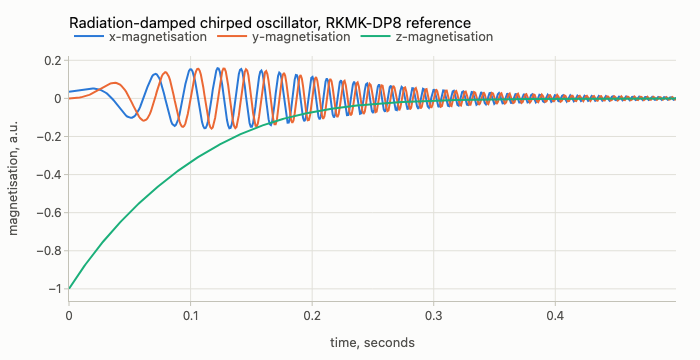

In [3]:
from spynach.plotting import plot_time_series

plot_time_series(
    np.linspace(0, 0.5, np_ref)[::4],
    mu_traj.real[:, ::4],  # every fourth point is enough for the figure
    names=["x-magnetisation", "y-magnetisation", "z-magnetisation"],
    xlabel="time, seconds",
    ylabel="magnetisation, a.u.",
    title="Radiation-damped chirped oscillator, RKMK-DP8 reference",
)

The 2-degree transverse seed grows at the net rate `rrd * |M_z| - r2`
(30 Hz at the start) while the damping term pushes M_z up from -1 and R1
relaxes it towards zero (this model relaxes to zero, not to the equilibrium
value); the transverse component peaks near 0.16 after about 0.1 s and then
decays, and the chirp winds it ever faster.

## Convergence of the methods

Each method is run on a series of grids and the relative error of the final
vector against the reference is fitted on log-log axes; the slope over the
finest third of the grids is the empirical convergence order. The MATLAB
script uses ten grids from 256 to 2048 points against a 4096-point reference;
five grids from 128 to 1024 points suffice to see the orders here, and
`examples/fundamentals/product_quadratures_2.py` runs the full size.

In [4]:
methods = ["PWCL", "LG2", "LG4", "LG4A", "RKMK4", "RKMK-DP5", "RKMK-DP8"]
labels = ["LP", "LG-2", "LG-4", "LG-4A", "RKMK4", "RKMK-DP5", "RKMK-DP8"]
grids = np.ceil(2.0 ** np.linspace(7, 10, 5)).astype(int)
bench = np.zeros((len(grids), len(methods)))
for k, npoints in enumerate(grids):
    for m, method in enumerate(methods):
        mu = integrate(method, int(npoints))[:, -1]
        bench[k, m] = np.linalg.norm(mu - mu_ref) / np.linalg.norm(mu_ref)

print("empirical convergence orders (slope of the log-log error curve):")
for m, label in enumerate(labels):
    slope = -np.polyfit(np.log(grids[2:]), np.log(bench[2:, m]), 1)[0]
    print(f"  {label:10s} {slope:5.2f}")

empirical convergence orders (slope of the log-log error curve):
  LP          0.99
  LG-2        2.00
  LG-4        3.98
  LG-4A       4.06
  RKMK4       3.94
  RKMK-DP5    5.56
  RKMK-DP8    9.72


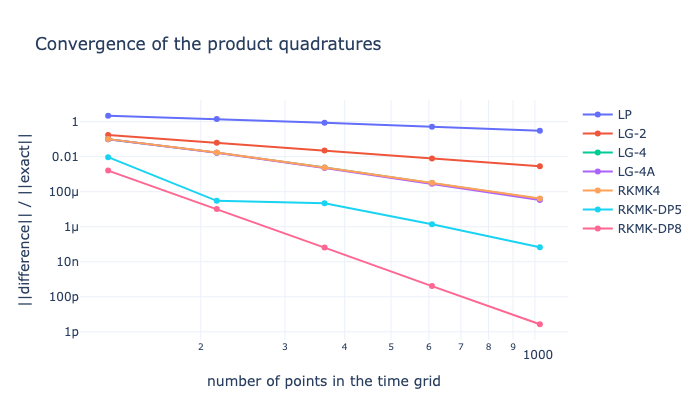

In [5]:
import plotly.graph_objects as go

fig = go.Figure()
for m, label in enumerate(labels):
    fig.add_trace(go.Scatter(x=grids, y=bench[:, m], mode="lines+markers", name=label))
fig.update_layout(
    title="Convergence of the product quadratures",
    xaxis={"title": "number of points in the time grid", "type": "log"},
    yaxis={"title": "||difference|| / ||exact||", "type": "log"},
    template="plotly_white",
    height=420,
)
fig

The slopes come out at the nominal orders: 1 for the piecewise-constant
step, 2 for `LG2`, 4 for `LG4`, `LG4A` and `RKMK4`, 5 for `RKMK-DP5` and 8
for `RKMK-DP8`, as the MATLAB script prints them.

## Choosing a method

- `'LG4'` has a good balance of accuracy and cost: three generator
  evaluations and four exponentials per step. It is Spinach's recommendation
  and the default to try first.
- `'RKMK-DP8'` reaches roundoff on coarse grids and is the method for a
  reference trajectory; it evaluates the generator thirteen times per step.
- `'PWCL'` is the piecewise-constant approximation, useful as a check of
  what the higher orders gain.
- The step must resolve the fastest motion of the generator as well as the
  fastest change of the state; for radiation damping that is the larger of
  the offset range and the damping rate.

## Radiation damping of a spin system: `radiation_damping`

The coil sees the transverse magnetisation of the isotope it is tuned to,
and the field of the induced current acts back on every spin of that
isotope. In the rotating frame this is a Hamiltonian term on the tuned
isotope, `w_x Ix + w_y Iy`, whose coefficients follow the state:

    w_x + i w_y = -i * rate * cos(phase) * exp(i phase) * (<Ix> + i <Iy>) / <Iz>_eq

`rate` is the radiation damping rate 1/T_rd in s⁻¹ at the equilibrium
magnetisation `<Iz>_eq` of a reference state, and `phase` the tuning phase
of the probe: 0 when the probe is tuned to the Larmor frequency, and
`atan(2 Q Δν / ν₀)` for a detuning Δν of a circuit of quality factor Q,
which reduces the feedback by `cos(phase)` and rotates it by `phase`. For
`H = w · I` one has `d<I>/dt = w × <I>`, so the term rotates the
magnetisation towards `+z` at a rate proportional to its own transverse
component: the Bloembergen-Pound mechanism (Phys. Rev. 95, 8 (1954)). The
feedback is unitary; relaxation, offsets and couplings come from the
ordinary Liouvillian `L0 = H + 1j * R`, and the sum is a generator that
depends on the state, which is what `iserstep` integrates.

`spynach.radiation_damping(spin_system, L0, isotope, rate, phase=0.0,
rho_eq=None, offsets=None, weights=None)` builds that generator as a
callable `L(t, rho)`. The reference state `rho_eq` defaults to the `Lz`
state of the isotope, the high-temperature equilibrium with unit
polarisation, which is also the usual starting point of a Spynach script;
pass `spynach.equilibrium(...)` or any other state to define the rate
against it, and start from a state scaled the same way. Since the feedback
is proportional to the actual magnetisation, a hyperpolarised or inverted
sample damps faster in proportion, and a negative `rate` or a phase beyond
90 degrees is active feedback. `offsets` (Hz) make an ensemble of
isochromats that share the coil (Liouville space only): the ensemble state
is the flattened stack of their vectors, built by `.stack(rho)` and read
back by `.columns(rho)`, `.observe(coil, rho)` detects with the weights,
and `line_weights(offsets, fwhm, "gaussian" | "lorentzian")` gives the
weights of a line shape. `.magnetisation(rho)` returns `(<Ix>, <Iy>,
<Iz>) / <Iz>_eq` of the tuned isotope.

Two helpers turn probe and sample into the parameters:
`spynach.rd_rate(spin_system, isotope, eta=, Q=, concentration=)` is
`μ₀ η Q |γ| M₀ / 2` with the Curie magnetisation of the isotope at that
concentration (mol/L), field and temperature, and
`spynach.rd_phase(spin_system, isotope, Q=, detuning=)` the tuning phase.
Water at 14.1 T in a probe with Q = 200 and a filling factor of 0.5:

In [6]:
water = spynach.create({"isotopes": ["1H"], "magnet": 14.1}, {})
rate = spynach.rd_rate(water, "1H", eta=0.5, Q=200, concentration=110.0)
print(f"1/T_rd = {rate:.0f} s^-1, T_rd = {1e3 / rate:.2f} ms;",
      f"phase at 100 kHz detuning: {spynach.rd_phase(water, '1H', Q=200, detuning=1e5):.3f} rad")

1/T_rd = 759 s^-1, T_rd = 1.32 ms; phase at 100 kHz detuning: 0.067 rad


The model takes the probe to respond at once: its ring-down time
`2Q/ω₀` (0.1 µs for the probe above) must be much shorter than T_rd, T2
and the inverse of the offsets, which holds for NMR probes up to a Q of a
few thousand. The strong-coupling regime of very high Q, where the coil
current needs its own equation of motion and the spectrum spans a sizeable
part of the probe bandwidth, is not modelled.

## The Bloembergen-Pound solution

One spin, no relaxation, a tuned probe: the magnetisation keeps its length,
`m_z = tanh(rate (t - t₀))` and `m_⊥ = sech(rate (t - t₀))`, with t₀ set
by the initial tilt; equivalently the tilt angle obeys
`tan(θ/2) = tan(θ₀/2) exp(-rate t)`. Starting 170 degrees from
equilibrium, the transverse seed grows until the magnetisation swings
through the transverse plane and settles along `+z`:

In [7]:
spin_system = spynach.basis(
    spynach.create({"isotopes": ["1H"], "magnet": 14.1}, {}), {"formalism": "sphten-liouv", "approximation": "none"}
)
Lz, Ly = spynach.state(spin_system, "Lz", "1H"), spynach.operator(spin_system, "Ly", "1H")
nothing = np.zeros((spin_system.basis.nstates,) * 2, dtype=complex)  # no offset, no relaxation


def tilted(theta):
    """The equilibrium magnetisation rotated by theta about y."""
    return spynach.step(spin_system, Ly, Lz, theta)


def evolve(spin_system, rd, rho, dt, nsteps, method="LG4"):
    """The magnetisation (<Ix>, <Iy>, <Iz>) / <Iz>_eq after every step, and the final state."""
    traces = []
    for n in range(nsteps):
        rho = iserstep(spin_system, rd, n * dt, method, rho, dt)
        traces.append(rd.magnetisation(rho))
    return np.array(traces), rho


rate, theta0, dt, nsteps = 50.0, np.pi * 170 / 180, 1e-4, 800
rd = spynach.radiation_damping(spin_system, nothing, "1H", rate)
m, _ = evolve(spin_system, rd, tilted(theta0), dt, nsteps)
t = np.arange(1, nsteps + 1) * dt
t0 = -np.arctanh(np.cos(theta0)) / rate
m_z, m_perp = np.tanh(rate * (t - t0)), 1 / np.cosh(rate * (t - t0))
print(f"largest deviation from the closed form: m_z {np.abs(m[:, 2] - m_z).max():.1e}, "
      f"m_perp {np.abs(np.hypot(m[:, 0], m[:, 1]) - m_perp).max():.1e}")

largest deviation from the closed form: m_z 3.0e-06, m_perp 1.7e-06


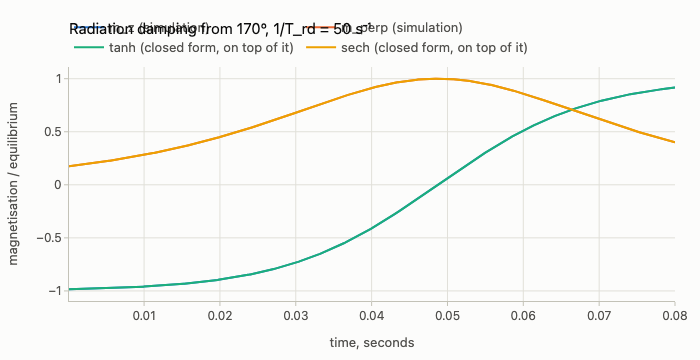

In [8]:
plot_time_series(
    t, [m[:, 2], np.hypot(m[:, 0], m[:, 1]), m_z, m_perp],
    names=["m_z (simulation)", "m_perp (simulation)", "tanh (closed form, on top of it)", "sech (closed form, on top of it)"],
    xlabel="time, seconds", ylabel="magnetisation / equilibrium",
    title=f"Radiation damping from 170°, 1/T_rd = {rate:g} s⁻¹",
)

The deviation is the integration error of `LG4` at this step; `RKMK-DP8`
takes it to roundoff. The closed form is exact for a single spin without
relaxation, and the same code runs unchanged with `L0 = H + 1j * R` of any
spin system.

## A detuned probe: damping and frequency pulling

With the probe detuned, the feedback field is no longer in quadrature with
the magnetisation. Its in-phase part still damps, at `rate cos²(phase)`,
and its other part shifts the precession frequency by
`rate cos(phase) sin(phase) / 2π`: the line moves away from the probe
resonance as it damps. A small tilt on a spin with T2 relaxation (no T1,
so that the longitudinal magnetisation driving the feedback stays at its
equilibrium value) and an offset of 40 Hz, recorded as a free induction
decay for three tuning phases:

In [9]:
relaxing = spynach.basis(
    spynach.create(
        {"isotopes": ["1H"], "magnet": 14.1},
        {"relaxation": ["t1_t2"], "r1_rates": [0.0], "r2_rates": [3.0], "rlx_keep": "diagonal", "equilibrium": "zero"},
    ),
    {"formalism": "sphten-liouv", "approximation": "none"},
)
L0 = 2 * np.pi * 40.0 * spynach.operator(relaxing, "Lz", "1H") + 1j * spynach.relaxation(relaxing)
rate, dt, nsteps = 40.0, 5e-4, 1000
fids, fitted = {}, {}
for phase in (0.0, 0.6, 1.0):
    rd = spynach.radiation_damping(relaxing, L0, "1H", rate, phase=phase)
    m, _ = evolve(relaxing, rd, spynach.step(relaxing, spynach.operator(relaxing, "Ly", "1H"),
                                             spynach.state(relaxing, "Lz", "1H"), 0.05), dt, nsteps)
    fids[phase] = m[:, 0] + 1j * m[:, 1]
    t = np.arange(1, nsteps + 1) * dt
    decay = -np.polyfit(t, np.log(np.abs(fids[phase])), 1)[0]
    shift = np.polyfit(t, np.unwrap(np.angle(fids[phase])), 1)[0] / (2 * np.pi)
    print(f"phase {phase:.1f}: decay {decay:6.2f} s^-1 (T2 + rate cos^2 = {3 + rate * np.cos(phase) ** 2:6.2f}),"
          f" line at {shift:6.2f} Hz (40 - rate cos sin / 2pi = {40 - rate * np.cos(phase) * np.sin(phase) / (2 * np.pi):6.2f})")

phase 0.0: decay  43.00 s^-1 (T2 + rate cos^2 =  43.00), line at  40.00 Hz (40 - rate cos sin / 2pi =  40.00)
phase 0.6: decay  30.24 s^-1 (T2 + rate cos^2 =  30.25), line at  37.03 Hz (40 - rate cos sin / 2pi =  37.03)
phase 1.0: decay  14.67 s^-1 (T2 + rate cos^2 =  14.68), line at  37.11 Hz (40 - rate cos sin / 2pi =  37.11)


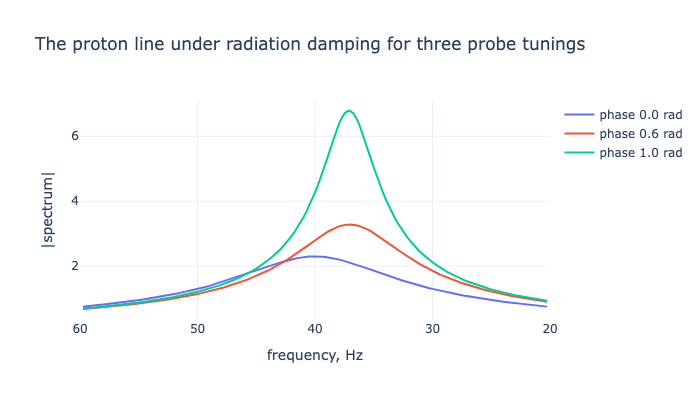

In [10]:
import plotly.graph_objects as go

freqs = np.fft.fftshift(np.fft.fftfreq(8 * nsteps, dt))
window = (freqs > 20) & (freqs < 60)
fig = go.Figure()
for phase, fid in fids.items():
    spectrum = np.abs(np.fft.fftshift(np.fft.fft(fid, 8 * nsteps)))
    fig.add_trace(go.Scatter(x=freqs[window], y=spectrum[window], mode="lines", name=f"phase {phase:.1f} rad"))
fig.update_layout(
    title="The proton line under radiation damping for three probe tunings",
    xaxis={"title": "frequency, Hz", "range": [60, 20]},  # NMR convention: frequency decreasing to the right
    yaxis={"title": "|spectrum|"},
    template="plotly_white",
    height=400,
)
fig

The fitted decay rates and positions agree with the linearised model. The
tilt is small here so that the damping stays in its linear regime; at
larger tilts the rate varies with `m_z` along the trajectory, which is the
nonlinearity the closed form of the previous section describes.

## An inhomogeneous line: isochromats

A line broadened by field inhomogeneity is a set of isochromats at
different offsets that share the coil. Their transverse magnetisations
dephase, which weakens the feedback; adding a `1/T2*` term to a single
Bloch vector gets this wrong, as the Concepts in Magnetic Resonance paper
of 2001 on the single-vector model points out, so the ensemble is
integrated as such. An inverted proton magnetisation with a Gaussian
line of 0, 20 and 80 Hz width at a damping rate of 80 s⁻¹:

In [11]:
offsets = np.linspace(-120, 120, 49)
rate, theta0, dt, nsteps = 80.0, np.pi * 170 / 180, 1e-4, 1000
recovery = {}
for fwhm in (None, 20.0, 80.0):
    if fwhm is None:
        rd = spynach.radiation_damping(spin_system, nothing, "1H", rate)
        rho = tilted(theta0)
    else:
        rd = spynach.radiation_damping(spin_system, nothing, "1H", rate, offsets=offsets,
                                       weights=spynach.line_weights(offsets, fwhm))
        rho = rd.stack(tilted(theta0))
    m, _ = evolve(spin_system, rd, rho, dt, nsteps)
    recovery[fwhm] = m[:, 2]
    print(f"line width {fwhm or 0:>4g} Hz: m_z = {m[-1, 2]:+.3f} after {nsteps * dt * 1e3:.0f} ms")

line width    0 Hz: m_z = +1.000 after 100 ms
line width   20 Hz: m_z = -0.004 after 100 ms
line width   80 Hz: m_z = -0.965 after 100 ms


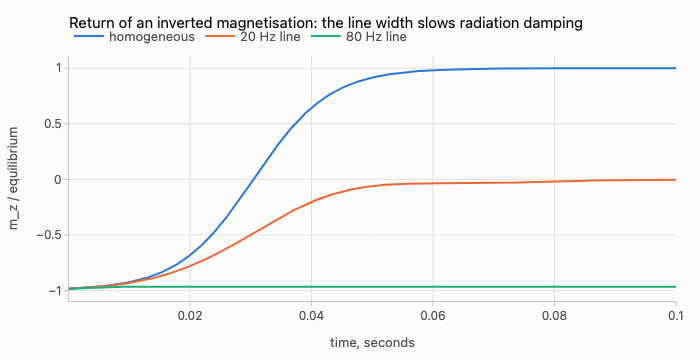

In [12]:
t = np.arange(1, nsteps + 1) * dt
plot_time_series(
    t, [recovery[None], recovery[20.0], recovery[80.0]],
    names=["homogeneous", "20 Hz line", "80 Hz line"],
    xlabel="time, seconds", ylabel="m_z / equilibrium",
    title="Return of an inverted magnetisation: the line width slows radiation damping",
)

The wider the line, the less of the transverse magnetisation survives in
phase to drive the coil, and the slower the return; the widest line barely
leaves the inverted state on this time scale.

## A coupled spin system against the line-by-line picture

The classical treatment of a multiplet assigns a Bloch vector to each
line, with its intensity as weight, and lets them share the coil. For a
weakly coupled pair that is exact: the doublet of a proton coupled to a
heteronucleus is two independent spin-1/2 subspaces at ±J/2. For a
strongly coupled pair it is not, because the eigenstates mix and the
feedback field acts on both spins. Two protons 12 Hz apart with J = 10 Hz
under radiation damping from 170 degrees, in the spin system and in the
line-by-line model built from the AB intensities (the latter is just an
isochromat ensemble of one spin at the four line positions):

In [13]:
dnu, J = 12.0, 10.0  # Hz
nu0 = spynach.isotopes.spin("1H")[0] * 14.1 / (2 * np.pi)  # proton Larmor frequency, Hz
ppm = [4.70, 4.70 + dnu / (nu0 * 1e-6)]
ab = spynach.create(
    {"isotopes": ["1H", "1H"], "magnet": 14.1}, {"zeeman": {"scalar": ppm}, "coupling": {"scalar": [[0, J], [0, 0]]}}
)
ab = spynach.assume(spynach.basis(ab, {"formalism": "sphten-liouv", "approximation": "none"}), "nmr")
H = spynach.frqoffset(ab, spynach.hamiltonian(ab), {"spins": ["1H"], "offset": [np.mean(ppm) * 1e-6 * nu0]})
rate, theta0, dt, nsteps = 60.0, np.pi * 170 / 180, 1e-4, 1000
rd_ab = spynach.radiation_damping(ab, H, "1H", rate)
rho_ab = spynach.step(ab, spynach.operator(ab, "Ly", "1H"), spynach.state(ab, "Lz", "1H"), theta0)
m_ab, _ = evolve(ab, rd_ab, rho_ab, dt, nsteps)

D = np.hypot(dnu, J)
lines = np.array([-(D + J) / 2, -(D - J) / 2, (D - J) / 2, (D + J) / 2])
intensities = np.array([1 - J / D, 1 + J / D, 1 + J / D, 1 - J / D])
rd_lines = spynach.radiation_damping(spin_system, nothing, "1H", rate, offsets=lines, weights=intensities)
m_lines, _ = evolve(spin_system, rd_lines, rd_lines.stack(tilted(theta0)), dt, nsteps)
print(f"AB system and line-by-line model differ by up to {np.abs(m_ab[:, 2] - m_lines[:, 2]).max():.3f} in m_z")

AB system and line-by-line model differ by up to 0.239 in m_z


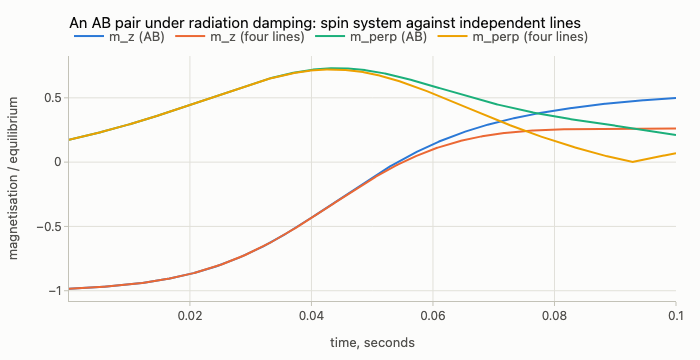

In [14]:
t = np.arange(1, nsteps + 1) * dt
plot_time_series(
    t, [m_ab[:, 2], m_lines[:, 2], np.hypot(m_ab[:, 0], m_ab[:, 1]), np.hypot(m_lines[:, 0], m_lines[:, 1])],
    names=["m_z (AB)", "m_z (four lines)", "m_perp (AB)", "m_perp (four lines)"],
    xlabel="time, seconds", ylabel="magnetisation / equilibrium",
    title="An AB pair under radiation damping: spin system against independent lines",
)

The two agree at first, while the feedback is weak and the lines precess
independently, and part company once the common field is strong enough to
mix the coupled states; the line-by-line picture overestimates the
dephasing. This is the regime the Barjat et al. multiplet experiments
(J. Magn. Reson. A 117, 109 (1995)) probe, and the reason a spin-system
treatment is needed once couplings are comparable to the damping rate.

## In the browser

The playground runs the doublet of the previous section with the shift
difference, the coupling, the damping rate, the probe phase, the tilt and
the line broadening in its parameter form
([`try.html#ex-rd`](https://ajerschow.github.io/spynach/try.html#ex-rd)),
and shows the proton spectrum with and without radiation damping next to
the return of the longitudinal magnetisation.